In [8]:
%pip install tensorflow matplotlib scikit-learn pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [9]:
import os
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)


TensorFlow version: 2.20.0
GPU available: False


2026-10-08 15:11:31.795557: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [10]:
BASE_DIR = "/home/unix/Anushka"
ZIP_PATH = os.path.join(BASE_DIR, "cats_and_dogs_filtered.zip")
DATASET_DIR = os.path.join(BASE_DIR, "cats_and_dogs_filtered")

if not os.path.isdir(DATASET_DIR):
    if not os.path.isfile(ZIP_PATH):
        raise FileNotFoundError(
            f"Dataset ZIP not found at: {ZIP_PATH}\n"
            "Please upload the downloaded ZIP file to this location."
        )

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(BASE_DIR)

print("Dataset directory:", DATASET_DIR)
print("Dataset contents:", os.listdir(DATASET_DIR))

Dataset directory: /home/unix/Anushka/cats_and_dogs_filtered
Dataset contents: ['train', 'validation', 'vectorize.py']


In [11]:
for split in ["train", "validation"]:
    for category in ["cats", "dogs"]:
        folder = os.path.join(DATASET_DIR, split, category)

        if not os.path.isdir(folder):
            raise FileNotFoundError(f"Missing folder: {folder}")

        count = sum(
            1 for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        )

        print(f"{split}/{category}: {count} images")

train/cats: 1000 images
train/dogs: 1000 images
validation/cats: 500 images
validation/dogs: 500 images


In [12]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_dir = os.path.join(DATASET_DIR, "train")
validation_dir = os.path.join(DATASET_DIR, "validation")

# Training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

# First half of the supplied validation images
val_ds = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.5,
    subset="training",
    seed=SEED,
    shuffle=True
)

# Second half: held-out test data
test_ds = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.5,
    subset="validation",
    seed=SEED,
    shuffle=False
)

class_names = train_ds.class_names
print("Class names:", class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Using 500 files for training.
Found 1000 files belonging to 2 classes.
Using 500 files for validation.
Class names: ['cats', 'dogs']


In [13]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

2026-10-12 10:53:04.549851: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


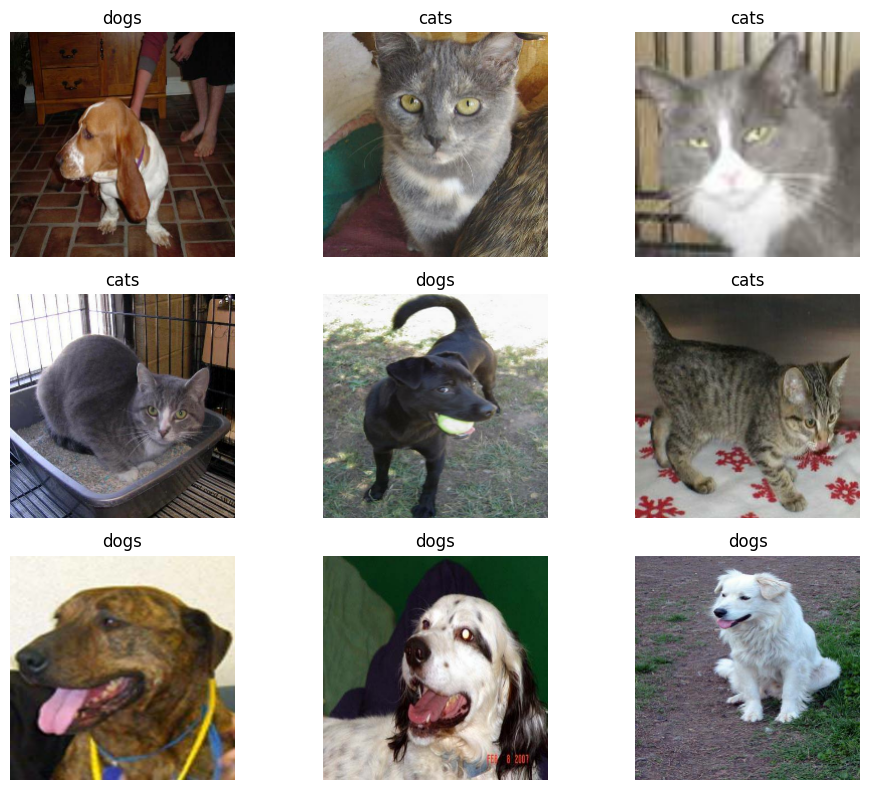

In [14]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label = int(labels[i].numpy()[0])
        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("Total ResNet50 layers:", len(base_model.layers))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 28s 0us/step
Total ResNet50 layers: 175


In [16]:
def build_model():
    base = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze pretrained layers for the first experiment
    base.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))

    # ResNet50 expects its specific preprocessing
    x = layers.Lambda(preprocess_input)(inputs)

    # Extract pretrained features
    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inputs, outputs)

    return model, base


model, base_model = build_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [17]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

start_time = time.time()

history_frozen = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

frozen_time = time.time() - start_time

print(f"Frozen model training time: {frozen_time:.2f} seconds")

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 105s 801ms/step - accuracy: 0.9265 - loss: 0.1858 - val_accuracy: 0.9880 - val_loss: 0.0488
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 98s 788ms/step - accuracy: 0.9870 - loss: 0.0500 - val_accuracy: 0.9900 - val_loss: 0.0344
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 98s 789ms/step - accuracy: 0.9875 - loss: 0.0396 - val_accuracy: 0.9860 - val_loss: 0.0311
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 98s 783ms/step - accuracy: 0.9925 - loss: 0.0288 - val_accuracy: 0.9860 - val_loss: 0.0264
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 97s 778ms/step - accuracy: 0.9945 - loss: 0.0200 - val_accuracy: 0.9960 - val_loss: 0.0205
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 99s 795ms/step - accuracy: 0.9960 - loss: 0.0193 - val_accuracy: 0.9900 - val_loss: 0.0205
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 98s 788ms/step - accuracy: 0.9965 - loss: 0.0146 - val_accuracy: 0.9900 - val_loss: 0.0188
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 99s 795ms/step - accuracy: 0.9975 - loss: 

In [18]:
frozen_loss, frozen_accuracy = model.evaluate(
    test_ds, verbose=1
)

print(f"Frozen model test loss: {frozen_loss:.4f}")
print(f"Frozen model test accuracy: {frozen_accuracy * 100:.2f}%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 617ms/step - accuracy: 0.9900 - loss: 0.0263
Frozen model test loss: 0.0263
Frozen model test accuracy: 99.00%


In [19]:
base_model.trainable = True

# Freeze earlier layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Trainable ResNet50 layers:",
      sum(layer.trainable for layer in base_model.layers))

Trainable ResNet50 layers: 21


In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

finetune_time = time.time() - start_time

print(f"Fine-tuning time: {finetune_time:.2f} seconds")

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.9975 - loss: 0.0086 - val_accuracy: 0.9960 - val_loss: 0.0139
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.9940 - val_loss: 0.0204
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 1.0000 - loss: 6.1166e-04 - val_accuracy: 0.9940 - val_loss: 0.0207
Fine-tuning time: 440.29 seconds


In [21]:
finetune_loss, finetune_accuracy = model.evaluate(
    test_ds, verbose=1
)

print(f"Fine-tuned test loss: {finetune_loss:.4f}")
print(f"Fine-tuned test accuracy: {finetune_accuracy * 100:.2f}%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 657ms/step - accuracy: 0.9880 - loss: 0.0403
Fine-tuned test loss: 0.0403
Fine-tuned test accuracy: 98.80%


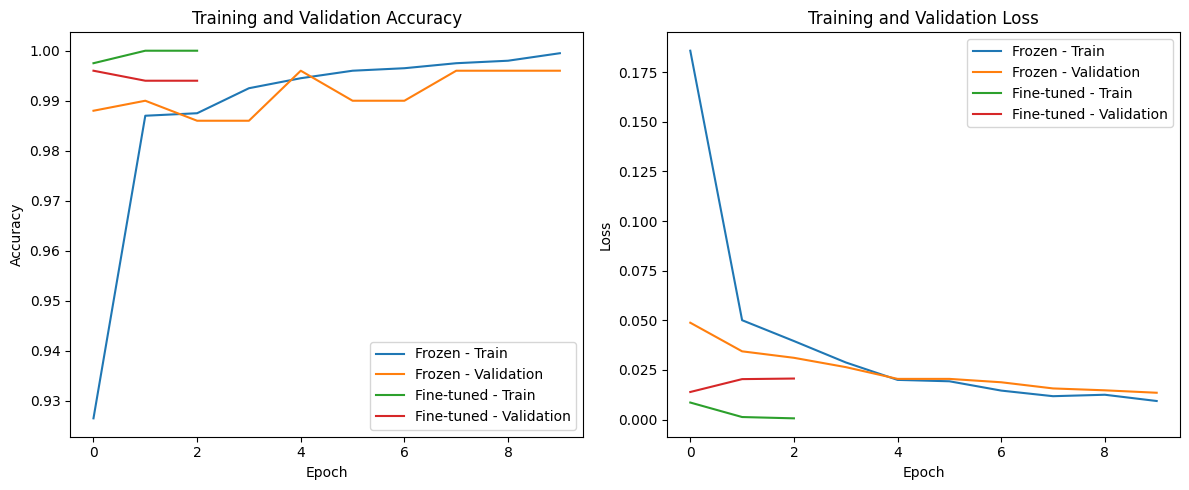

In [22]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_frozen.history["accuracy"], label="Frozen - Train")
plt.plot(history_frozen.history["val_accuracy"], label="Frozen - Validation")
plt.plot(history_finetune.history["accuracy"], label="Fine-tuned - Train")
plt.plot(history_finetune.history["val_accuracy"], label="Fine-tuned - Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_frozen.history["loss"], label="Frozen - Train")
plt.plot(history_frozen.history["val_loss"], label="Frozen - Validation")
plt.plot(history_finetune.history["loss"], label="Fine-tuned - Train")
plt.plot(history_finetune.history["val_loss"], label="Fine-tuned - Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
results = pd.DataFrame({
    "Experiment": [
        "Frozen ResNet50",
        "Fine-tuned ResNet50"
    ],
    "Test Accuracy (%)": [
        frozen_accuracy * 100,
        finetune_accuracy * 100
    ],
    "Test Loss": [
        frozen_loss,
        finetune_loss
    ],
    "Training Time (seconds)": [
        frozen_time,
        finetune_time
    ]
})

print(results.round(4).to_string(index=False))

         Experiment  Test Accuracy (%)  Test Loss  Training Time (seconds)
    Frozen ResNet50               99.0     0.0263                 989.5441
Fine-tuned ResNet50               98.8     0.0403                 440.2873


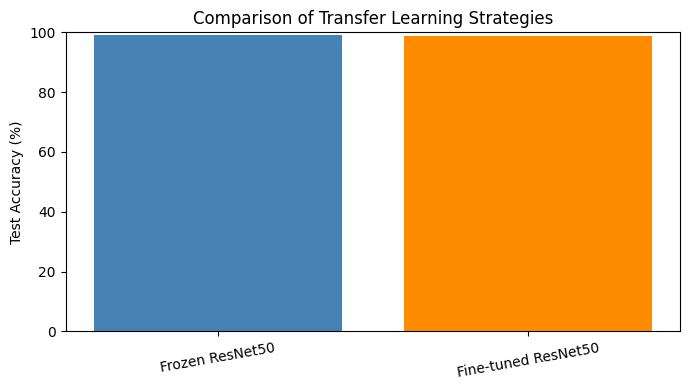

In [24]:
plt.figure(figsize=(7, 4))

plt.bar(
    results["Experiment"],
    results["Test Accuracy (%)"],
    color=["steelblue", "darkorange"]
)

plt.ylabel("Test Accuracy (%)")
plt.title("Comparison of Transfer Learning Strategies")
plt.ylim(0, 100)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [26]:
y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

y_prob = model.predict(test_ds, verbose=1).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))


2026-10-12 11:43:24.907694: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


32/32 ━━━━━━━━━━━━━━━━━━━━ 23s 683ms/step
              precision    recall  f1-score   support

        cats       0.00      0.00      0.00         0
        dogs       1.00      0.99      0.99       500

    accuracy                           0.99       500
   macro avg       0.50      0.49      0.50       500
weighted avg       1.00      0.99      0.99       500



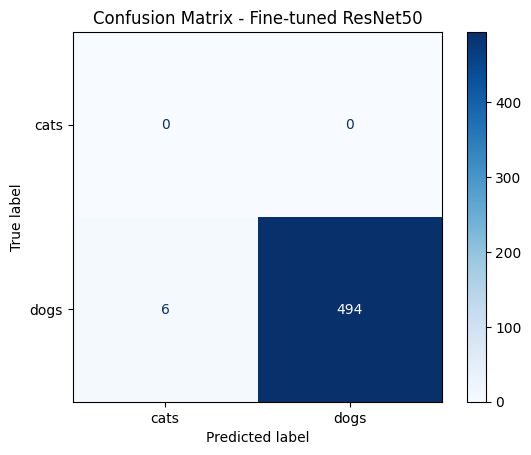

In [29]:



cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Fine-tuned ResNet50")
plt.show()